In [1]:
from pathlib import Path
import sys
import importlib.util
if importlib.util.find_spec('duckdb') is None:
    raise ModuleNotFoundError('duckdb is missing from this Jupyter kernel; run %pip install -r requirements.txt, then restart the kernel.')
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT=Path.cwd()
if not (PROJECT_ROOT/'ypipe').is_dir(): PROJECT_ROOT=PROJECT_ROOT.parent
sys.path.insert(0,str(PROJECT_ROOT))
from ypipe import config,cluster

SEED=42
np.random.seed(SEED)
MIN_USERS=config.MIN_USERS_CLUSTER
MAX_K=config.MAX_K
N_STABILITY_SEEDS=10  # so sánh nhiều khởi tạo trên cùng dữ liệu
N_BOOTSTRAPS=20  # số mẫu bootstrap để xem độ ổn định với nhóm nhỏ
BOOTSTRAP_FRACTION=0.8
MIN_ITEM_EVENTS=10  # chỉ vẽ nội dung có ít nhất 10 lượt mở để giảm ô lift nhiễu
N_TOP_ITEMS=10
config.DATA.mkdir(parents=True,exist_ok=True)
_previous_con = globals().get('con')
if _previous_con is not None:
    try:
        _previous_con.close()
    except Exception:
        pass
class _NotebookQueryResult:
    def __init__(self, frame):
        self._frame = frame
    def df(self):
        return self._frame.copy()
    def fetchdf(self):
        return self._frame.copy()
    def fetchone(self):
        if self._frame.empty:
            return None
        return tuple(self._frame.iloc[0].tolist())
    def fetchall(self):
        return list(self._frame.itertuples(index=False, name=None))

class _NotebookReadOnlyDB:
    """Run each read query on a short-lived connection to avoid retaining a file lock."""
    def __init__(self, path):
        self.path = Path(path)
    def execute(self, sql, parameters=None):
        if not self.path.exists():
            if sql.strip().lower() == 'show tables':
                return _NotebookQueryResult(pd.DataFrame({'name': pd.Series(dtype='object')}))
            return _NotebookQueryResult(pd.DataFrame())
        db = duckdb.connect(str(self.path), read_only=True)
        try:
            result = db.execute(sql) if parameters is None else db.execute(sql, parameters)
            frame = result.fetchdf()
        finally:
            db.close()
        return _NotebookQueryResult(frame)
    def close(self):
        # Queries already close their own connection before returning.
        return None

con=_NotebookReadOnlyDB(config.DB_PATH)
TABLES=set(con.execute('SHOW TABLES').fetchdf()['name'])
print(f'Database: {config.DB_PATH} | seed={SEED} | ngưỡng user={MIN_USERS} | max k={MAX_K}')

Database: D:\project\bigdata\data\warehouse.duckdb | seed=42 | ngưỡng user=4 | max k=6


# Phân khúc người dùng — Stage 5

## Câu hỏi
Có nhóm hành vi người xem nào tách biệt ổn định không? Các nhóm này khác nhau ra sao về loại phiên và nội dung thường mở?

## Phương pháp
Tái lập KMeans trên đúng danh sách `cluster.BEHAV` hiện có và topic-share có trọng số cấu hình; không thêm session-share vào mô hình hành vi cũ. So sánh k bằng silhouette, Davies–Bouldin và inertia; đánh giá độ ổn định bằng nhiều seed và bootstrap ARI. Phân cụm phiên P5 được mô tả riêng bằng tỷ lệ các loại phiên trong `user_features`. Từ “khách hàng” ở đây chỉ cụm người xem; YouTube API không cung cấp nhân khẩu học người xem.

In [2]:
uf=con.execute('SELECT * FROM user_features').df() if 'user_features' in TABLES else pd.DataFrame()
facts=con.execute('SELECT * FROM video_facts').df() if 'video_facts' in TABLES else pd.DataFrame()
raw=con.execute('SELECT user_id,video_id FROM watch_raw').df() if 'watch_raw' in TABLES else pd.DataFrame()
topic_labels=con.execute('SELECT topic_id,label AS topic_label FROM topics').df() if 'topics' in TABLES else pd.DataFrame(columns=['topic_id','topic_label'])

cluster_assign=pd.DataFrame(columns=['user_id','cluster','pc1','pc2'])
metric_rows=[]; metric_table=pd.DataFrame(); feature_names=[]; Z=None; user_order=[]
if len(uf)>=MIN_USERS:
    feature_names=[c for c in cluster.BEHAV if c in uf and uf[c].notna().sum()>=max(3,0.8*len(uf))]
    X=uf[feature_names].astype(float).copy().fillna(uf[feature_names].astype(float).median())
    feature_names=[c for c in feature_names if X[c].std()>1e-9]
    if feature_names:
        Zb=StandardScaler().fit_transform(X[feature_names])
        Z=Zb
        topic_cols=[c for c in uf if c.startswith('topic_') and c!='topic_drift']
        if topic_cols:
            T=uf[topic_cols].fillna(0)
            T=T.loc[:,T.std()>1e-9]
            if T.shape[1]: Z=np.hstack([Zb,StandardScaler().fit_transform(T)*config.TOPIC_WEIGHT])
        for k in range(2,min(MAX_K,len(uf)-1)+1):
            model=KMeans(n_clusters=k,n_init=20,random_state=SEED).fit(Z)
            if len(np.unique(model.labels_))<2 or len(np.unique(model.labels_))>=len(uf): continue
            metric_rows.append({'k':k,'silhouette':silhouette_score(Z,model.labels_),
                                'davies_bouldin':davies_bouldin_score(Z,model.labels_),'inertia':model.inertia_})
        if metric_rows:
            metric_table=pd.DataFrame(metric_rows).sort_values('k')
            selected_k=int(metric_table.sort_values('silhouette',ascending=False).iloc[0]['k'])
            baseline=KMeans(n_clusters=selected_k,n_init=20,random_state=SEED).fit(Z)
            pcs=PCA(n_components=2,random_state=SEED).fit_transform(Z) if Z.shape[1]>=2 else np.c_[Z[:,0],np.zeros(len(Z))]
            cluster_assign=pd.DataFrame({'user_id':uf.user_id.to_numpy(),'cluster':baseline.labels_,
                                         'pc1':pcs[:,0],'pc2':pcs[:,1]})
            base_labels=baseline.labels_
            user_order=sorted(uf.user_id.astype(str).tolist())
        else: metric_table=pd.DataFrame()
    else: metric_table=pd.DataFrame()
else:
    metric_table=pd.DataFrame()
    print(f'Có {len(uf)} user; cần ít nhất {MIN_USERS} để phân cụm.')

if len(cluster_assign):
    code_map={uid:f'U{i+1}' for i,uid in enumerate(user_order)}
    cluster_assign['user_code']=cluster_assign.user_id.map(code_map)
    anon_assign=cluster_assign[['user_code','cluster','pc1','pc2']].copy()
    display(metric_table)
    display(anon_assign.sort_values('user_code'))
else:
    print('Chưa đủ biến thiên hoặc số người dùng để tạo cụm; các cell sau sẽ hiển thị ghi chú tương ứng.')

,k,silhouette,davies_bouldin,inertia
0,2,0.209306,1.532711,197.300232
1,3,0.189428,1.204611,156.247596
2,4,0.201506,1.069833,127.409183
3,5,0.202127,0.996180,102.279557
4,6,0.174880,0.895739,85.552163


,user_code,cluster,pc1,pc2
0,U1,1,2.765575,1.104320
9,U10,0,-4.131210,-0.134053
10,U11,0,-0.373463,3.056850
11,U12,1,1.092199,-0.921950
12,U13,0,-2.168871,0.264955
13,U14,0,-1.014817,0.492213
14,U15,0,-1.801369,0.821791
15,U16,0,-1.626971,-1.422092
16,U17,0,-1.117590,-0.381388
1,U2,1,2.120331,-0.431197


## Kết quả: chọn k và độ ổn định
Silhouette cao hơn và Davies–Bouldin thấp hơn thường cho thấy cụm tách nhau rõ hơn; inertia giảm khi tăng k nên dùng như biểu đồ elbow, không chọn k chỉ theo inertia. ARI gần 1 nghĩa là hai cách gán tương tự; nhóm người dùng ít khiến chỉ số dễ biến động.

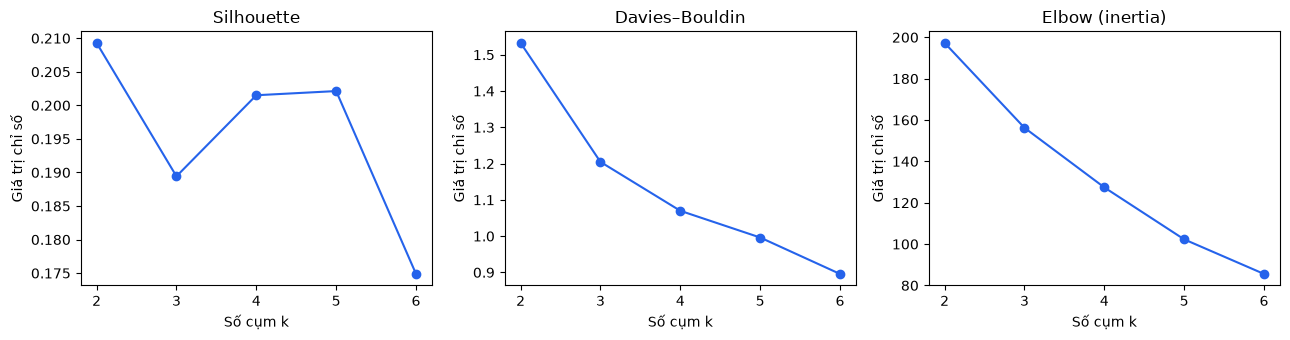

,Kiểm tra,Số lần,ARI trung vị,ARI thấp nhất
0,Nhiều seed,10,1.0,1.000000
1,Bootstrap 80%,20,1.0,0.275163


In [3]:
if len(cluster_assign) and len(metric_table):
    fig,axes=plt.subplots(1,3,figsize=(13,3.5))
    for ax,col,title in zip(axes,['silhouette','davies_bouldin','inertia'],['Silhouette','Davies–Bouldin','Elbow (inertia)']):
        ax.plot(metric_table.k,metric_table[col],marker='o',color='#2563eb')
        ax.set_title(title); ax.set_xlabel('Số cụm k'); ax.set_ylabel('Giá trị chỉ số'); ax.set_xticks(metric_table.k)
    plt.tight_layout(); plt.show()
    seed_aris=[]
    for seed in range(SEED,SEED+N_STABILITY_SEEDS):
        labels=KMeans(n_clusters=selected_k,n_init=20,random_state=seed).fit_predict(Z)
        seed_aris.append(adjusted_rand_score(base_labels,labels))
    rng=np.random.RandomState(SEED); bootstrap_aris=[]
    sample_n=max(selected_k+1,int(np.ceil(BOOTSTRAP_FRACTION*len(uf))))
    for _ in range(N_BOOTSTRAPS):
        idx=np.sort(rng.choice(len(uf),size=min(sample_n,len(uf)),replace=False))
        if len(idx)<=selected_k: continue
        labels=KMeans(n_clusters=selected_k,n_init=20,random_state=int(rng.randint(0,2**31-1))).fit_predict(Z[idx])
        if len(np.unique(labels))>=2:
            bootstrap_aris.append(adjusted_rand_score(base_labels[idx],labels))
    stability=pd.DataFrame([
        {'Kiểm tra':'Nhiều seed','Số lần':len(seed_aris),'ARI trung vị':np.median(seed_aris),'ARI thấp nhất':np.min(seed_aris)},
        {'Kiểm tra':'Bootstrap 80%','Số lần':len(bootstrap_aris),
         'ARI trung vị':np.median(bootstrap_aris) if bootstrap_aris else np.nan,
         'ARI thấp nhất':np.min(bootstrap_aris) if bootstrap_aris else np.nan}
    ])
    display(stability)
    if np.median(seed_aris)<0.5 or (bootstrap_aris and np.median(bootstrap_aris)<0.5):
        print('Độ ổn định thấp: xem cụm như mô tả thăm dò, không xem là nhóm người cố định.')
else:
    print('Không có kết quả phân cụm để kiểm tra độ ổn định.')

## Kết quả: hồ sơ nhóm và loại phiên
Mã người trong biểu đồ dùng U1, U2, …; bảng hồ sơ nhóm báo cáo trung bình đặc trưng đã chuẩn hóa. Các cột `session_type_*` là tỷ lệ phiên theo cụm phiên P5, không thay thế phân cụm hành vi người dùng.

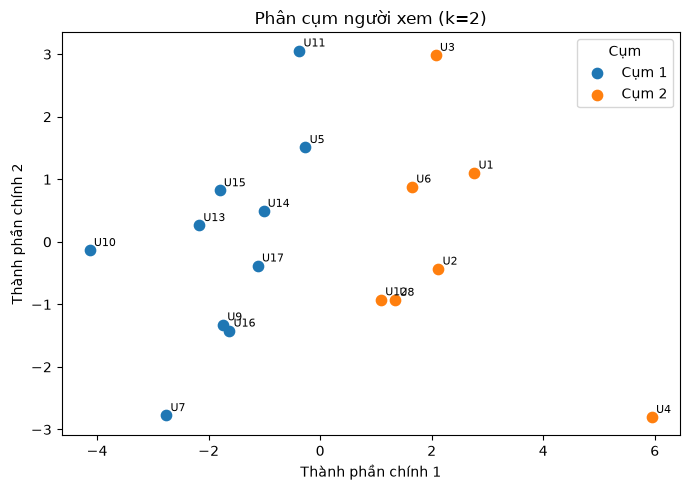

,videos_per_active_day,active_day_ratio,night_ratio,weekend_boost,sessions_per_active_day,avg_videos_per_session,repeat_ratio,channel_top5_share,channel_entropy,topic_drift,shorts_ratio,long_ratio,category_entropy
cluster,,,,,,,,,,,,,
Cụm 1,7.280998,0.348274,0.207038,0.958683,1.797726,4.013578,0.175033,0.205029,0.876543,0.076513,0.295682,0.218258,0.664766
Cụm 2,57.431958,0.892790,0.233995,1.073154,4.110773,13.838693,0.322681,0.102627,0.848415,0.028152,0.416697,0.139981,0.673929


,Loại phiên 0,Loại phiên 1,Loại phiên 2,Loại phiên 3,Loại phiên 4,Loại phiên 5
Cụm người xem 1,0.231510,0.202514,0.120045,0.009396,0.253976,0.182558
Cụm người xem 2,0.092234,0.252004,0.202689,0.113280,0.092251,0.247543


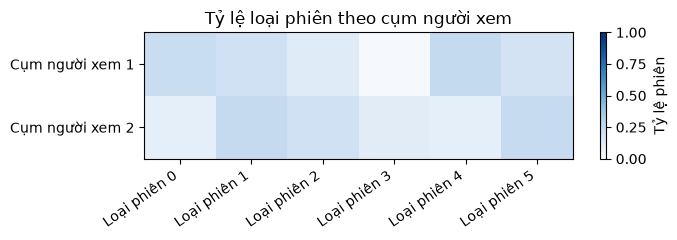

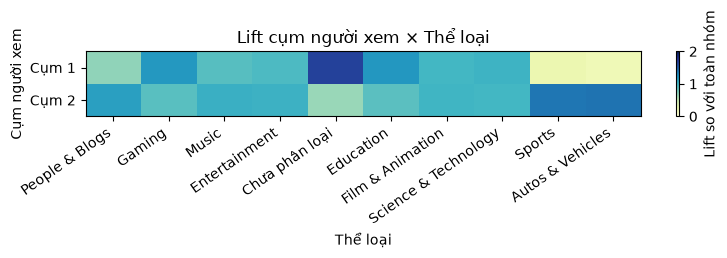

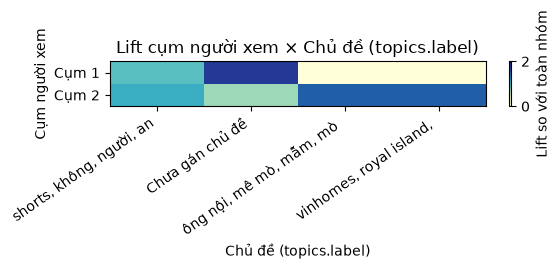

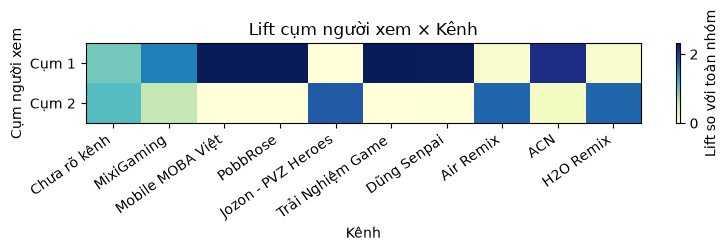

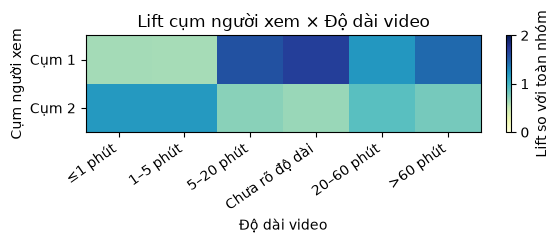

In [4]:
if len(cluster_assign):
    fig,ax=plt.subplots(figsize=(7,5)); cmap=plt.get_cmap('tab10')
    for c,g in cluster_assign.groupby('cluster'):
        ax.scatter(g.pc1,g.pc2,label=f'Cụm {c+1}',s=55,color=cmap(c))
        for row in g.itertuples(): ax.annotate(code_map[row.user_id],(row.pc1,row.pc2),fontsize=8,xytext=(3,3),textcoords='offset points')
    ax.set_title(f'Phân cụm người xem (k={selected_k})'); ax.set_xlabel('Thành phần chính 1'); ax.set_ylabel('Thành phần chính 2'); ax.legend(title='Cụm')
    plt.tight_layout(); plt.show()
    profile_data=uf.merge(cluster_assign[['user_id','cluster']],on='user_id')
    display(profile_data.groupby('cluster')[feature_names].mean().rename(index=lambda i:f'Cụm {i+1}'))
    session_cols=[c for c in uf.columns if c.startswith('session_type_')]
    if session_cols:
        session_profile=profile_data.groupby('cluster')[session_cols].mean()
        session_profile.index=[f'Cụm người xem {i+1}' for i in session_profile.index]
        session_profile.columns=[c.replace('session_type_','Loại phiên ') for c in session_profile.columns]
        display(session_profile)
        fig,ax=plt.subplots(figsize=(7,max(2.5,0.5*len(session_profile))))
        im=ax.imshow(session_profile.values,aspect='auto',cmap='Blues',vmin=0,vmax=1)
        ax.set_yticks(range(len(session_profile))); ax.set_yticklabels(session_profile.index)
        ax.set_xticks(range(len(session_profile.columns))); ax.set_xticklabels(session_profile.columns,rotation=35,ha='right')
        ax.set_title('Tỷ lệ loại phiên theo cụm người xem'); fig.colorbar(im,ax=ax,label='Tỷ lệ phiên')
        plt.tight_layout(); plt.show()
    else: print('Bảng user_features chưa có cột tỷ lệ loại phiên; chạy pipeline P5 trước.')
else:
    profile_data=pd.DataFrame(); session_cols=[]

if len(cluster_assign) and len(raw) and len(facts):
    item_events=raw.merge(facts,on='video_id',how='inner').merge(cluster_assign[['user_id','cluster']],on='user_id',how='inner')
    if len(topic_labels) and 'topic_id' in item_events:
        item_events=item_events.merge(topic_labels,on='topic_id',how='left')
        item_events['topic_item']=item_events['topic_label'].fillna('Chưa gán chủ đề')
    else: item_events['topic_item']='Chưa gán chủ đề'
    item_events['category_item']=item_events['category_name'].fillna('Chưa phân loại')
    item_events['channel_item']=item_events['channel_name'].fillna('Chưa rõ kênh')
    item_events['length_item']=pd.cut(item_events['duration_sec'],[-np.inf,60,300,1200,3600,np.inf],
        labels=['≤1 phút','1–5 phút','5–20 phút','20–60 phút','>60 phút']).astype('object').fillna('Chưa rõ độ dài')

    def lift_matrix(data,column):
        counts=data.groupby(['cluster',column]).size().unstack(fill_value=0)
        global_counts=counts.sum(axis=0)
        keep=global_counts[global_counts>=MIN_ITEM_EVENTS].sort_values(ascending=False).head(N_TOP_ITEMS).index
        counts=counts.reindex(columns=keep,fill_value=0)
        if counts.empty or counts.shape[1]==0: return pd.DataFrame()
        within=counts.div(counts.sum(axis=1).replace(0,np.nan),axis=0)
        overall=counts.sum(axis=0)/counts.to_numpy().sum()
        return within.div(overall.replace(0,np.nan),axis=1)

    dimensions=[('category_item','Thể loại'),('topic_item','Chủ đề (topics.label)'),
                ('channel_item','Kênh'),('length_item','Độ dài video')]
    lift_tables={}
    for column,label in dimensions:
        matrix=lift_matrix(item_events,column); lift_tables[label]=matrix
        if matrix.empty:
            print(f'Chưa có mục {label.lower()} đạt {MIN_ITEM_EVENTS} lượt mở.')
            continue
        fig,ax=plt.subplots(figsize=(max(6,0.8*matrix.shape[1]),max(2.5,0.55*matrix.shape[0])))
        im=ax.imshow(matrix.values,aspect='auto',cmap='YlGnBu',vmin=0,vmax=max(2,float(np.nanpercentile(matrix.values,90))))
        ax.set_yticks(range(len(matrix.index))); ax.set_yticklabels([f'Cụm {int(c)+1}' for c in matrix.index])
        ax.set_xticks(range(len(matrix.columns))); ax.set_xticklabels([str(x)[:24] for x in matrix.columns],rotation=35,ha='right')
        ax.set_title(f'Lift cụm người xem × {label}'); ax.set_xlabel(label); ax.set_ylabel('Cụm người xem')
        fig.colorbar(im,ax=ax,label='Lift so với toàn nhóm'); plt.tight_layout(); plt.show()
else:
    item_events=pd.DataFrame(); lift_tables={}
    print('Chưa đủ bảng user_features/video_facts để tính lift theo nội dung.')

con.close()

## Insight
Mô tả “nội dung cho nhóm nào” bằng lift: lift lớn hơn 1 nghĩa là tỷ trọng lượt mở mục đó trong cụm cao hơn tỷ trọng toàn nhóm. Nhóm là phân khúc hành vi trong mẫu này, không phải phân khúc nhân khẩu học hay khách hàng được nhận diện ngoài đời.

## Hạn chế
Với khoảng 10+ người, cả silhouette lẫn độ ổn định có thể thấp; luôn báo cáo ARI seed/bootstrap và không diễn giải cụm như loại người cố định. Lift dựa trên lượt mở nên người xem nhiều có trọng số lớn hơn. API không có nhãn nhân khẩu học; category là metadata yếu, topic là cụm title tự phát hiện, channel có thể thiếu. KMeans nhạy với chuẩn hóa, k và cỡ mẫu. Không suy luận nhân quả từ khác biệt giữa cụm.